<a href="https://colab.research.google.com/github/vennela2604/GitGitubWorkShop-26/blob/main/soil_health.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analysis of Soil Health Parameters and Crop Productivity

## Project Overview
This project explores the relationship between various soil health parameters (pH, Organic Carbon, Nitrogen, Phosphorus, Potassium) and crop productivity across different Indian states.

## Objectives
- Analyze soil health parameter variations across states.
- Study correlations between soil nutrients and crop productivity.
- Visualize trends using Python data science libraries.

## Technology Stack
- **Python**
- **Google Colab**
- **Pandas & NumPy** (Data manipulation)
- **Matplotlib & Seaborn** (Data visualization)

## How to Run
1. Download the `Soil_Health_Project.ipynb` file from this repository.
2. Open [Google Colab](https://colab.research.google.com/).
3. Upload the notebook and run the cells sequentially.

In [1]:
# Import the essential Python libraries for our project
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seaborn_module

# Print a happy confirmation message so we know it worked!
print("Libraries imported successfully! Ready for action.")

Libraries imported successfully! Ready for action.


In [2]:
import pandas as pd
import numpy as np

# Setting a random seed so your numbers are consistent and repeatable
np.random.seed(42)

# List of major Indian agricultural states
states = ['Punjab', 'Haryana', 'Uttar Pradesh', 'Madhya Pradesh', 'Maharashtra',
          'Bihar', 'West Bengal', 'Karnataka', 'Andhra Pradesh', 'Tamil Nadu',
          'Rajasthan', 'Gujarat', 'Odisha', 'Telangana', 'Kerala']

# Generate 180 rows of data (matching your project description)
n_rows = 180
data = {
    'State': np.random.choice(states, n_rows),
    'Year': np.random.choice(range(2000, 2012), n_rows),
    'Soil_pH': np.round(np.random.uniform(5.5, 8.5, n_rows), 2),           # pH scale usually 5.5 to 8.5
    'Organic_Carbon': np.round(np.random.uniform(0.3, 1.5, n_rows), 2),    # in percentage (%)
    'Nitrogen': np.round(np.random.uniform(100, 350, n_rows), 1),        # kg/ha
    'Phosphorus': np.round(np.random.uniform(10, 60, n_rows), 1),        # kg/ha
    'Potassium': np.round(np.random.uniform(120, 400, n_rows), 1),       # kg/ha
    'Crop_Productivity': np.round(np.random.uniform(1.5, 5.0, n_rows), 2)  # tons per hectare
}

# Convert our data into a Pandas DataFrame (our table)
df = pd.DataFrame(data)

# Save it locally in Colab as a CSV file (just like uploading a real file!)
df.to_csv('soil_health_crop_productivity.csv', index=False)

print("Dataset created and saved successfully!")
print(f"Total rows and columns in our dataset: {df.shape}")


Dataset created and saved successfully!
Total rows and columns in our dataset: (180, 8)


In [3]:
# Display the first 5 rows of our dataset
print("--- First 5 Rows of the Dataset ---")
display(df.head())

# Check data types and column information
print("\n--- Dataset Information ---")
df.info()

--- First 5 Rows of the Dataset ---


,State,Year,Soil_pH,Organic_Carbon,Nitrogen,Phosphorus,Potassium,Crop_Productivity
0,West Bengal,2006,7.46,0.75,199.1,41.4,395.6,2.28
1,Madhya Pradesh,2006,6.17,1.23,255.5,26.7,267.2,3.38
2,Odisha,2010,7.64,0.71,315.6,17.0,168.1,3.58
3,Kerala,2008,6.21,1.42,337.4,49.7,196.2,3.53
4,Rajasthan,2009,6.48,1.33,136.8,41.0,125.1,1.82



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   State              180 non-null    object 
 1   Year               180 non-null    int64  
 2   Soil_pH            180 non-null    float64
 3   Organic_Carbon     180 non-null    float64
 4   Nitrogen           180 non-null    float64
 5   Phosphorus         180 non-null    float64
 6   Potassium          180 non-null    float64
 7   Crop_Productivity  180 non-null    float64
dtypes: float64(6), int64(1), object(1)
memory usage: 11.4+ KB


In [4]:
# 1. Check for missing values in any column
print("--- Missing Values Check ---")
print(df.isnull().sum())

# 2. Check for duplicate rows
duplicates_count = df.duplicated().sum()
print(f"\n--- Duplicate Rows Check ---\nTotal duplicate rows found: {duplicates_count}")

# 3. Quick check of summary statistics to spot any unusual/invalid values
print("\n--- Summary Statistics (Min, Max, Averages) ---")
display(df.describe())

--- Missing Values Check ---
State                0
Year                 0
Soil_pH              0
Organic_Carbon       0
Nitrogen             0
Phosphorus           0
Potassium            0
Crop_Productivity    0
dtype: int64

--- Duplicate Rows Check ---
Total duplicate rows found: 0

--- Summary Statistics (Min, Max, Averages) ---


,Year,Soil_pH,Organic_Carbon,Nitrogen,Phosphorus,Potassium,Crop_Productivity
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,2005.405556,7.018167,0.948389,214.256111,34.000000,263.407778,3.263389
std,3.577861,0.874514,0.365865,70.028151,14.296595,84.880700,1.033995
min,2000.000000,5.540000,0.310000,105.000000,10.200000,123.100000,1.520000
25%,2002.000000,6.307500,0.677500,149.825000,21.175000,185.350000,2.395000
50%,2006.000000,7.105000,0.970000,207.150000,32.900000,266.250000,3.345000
75%,2008.000000,7.712500,1.280000,267.850000,46.100000,338.775000,4.160000
max,2011.000000,8.470000,1.500000,347.500000,59.800000,399.400000,4.990000


In [5]:
# Group our data by State and calculate the average (mean) for each soil parameter and crop productivity
state_summary = df.groupby('State')[['Soil_pH', 'Organic_Carbon', 'Nitrogen', 'Phosphorus', 'Potassium', 'Crop_Productivity']].mean()

# Round the numbers to 2 decimal places so they are easy to read
state_summary = state_summary.round(2)

# Sort the table by Crop Productivity in descending order (highest to lowest)
state_summary_sorted = state_summary.sort_values(by='Crop_Productivity', ascending=False)

print("--- Average Soil Health & Crop Productivity by State ---")
display(state_summary_sorted)

--- Average Soil Health & Crop Productivity by State ---


,Soil_pH,Organic_Carbon,Nitrogen,Phosphorus,Potassium,Crop_Productivity
State,,,,,,
Haryana,6.36,1.04,192.85,34.75,312.61,3.98
Andhra Pradesh,7.42,1.07,220.72,31.99,264.78,3.85
Gujarat,6.81,0.85,222.96,34.39,252.54,3.48
Rajasthan,6.79,0.95,205.10,31.05,252.90,3.36
Tamil Nadu,6.94,0.91,205.22,29.37,243.19,3.28
Punjab,7.07,0.88,213.92,29.42,272.96,3.22
West Bengal,7.10,0.78,194.95,34.59,267.92,3.20
Telangana,6.93,0.98,220.61,36.02,225.55,3.18
Kerala,6.98,0.92,231.17,38.77,259.27,3.10


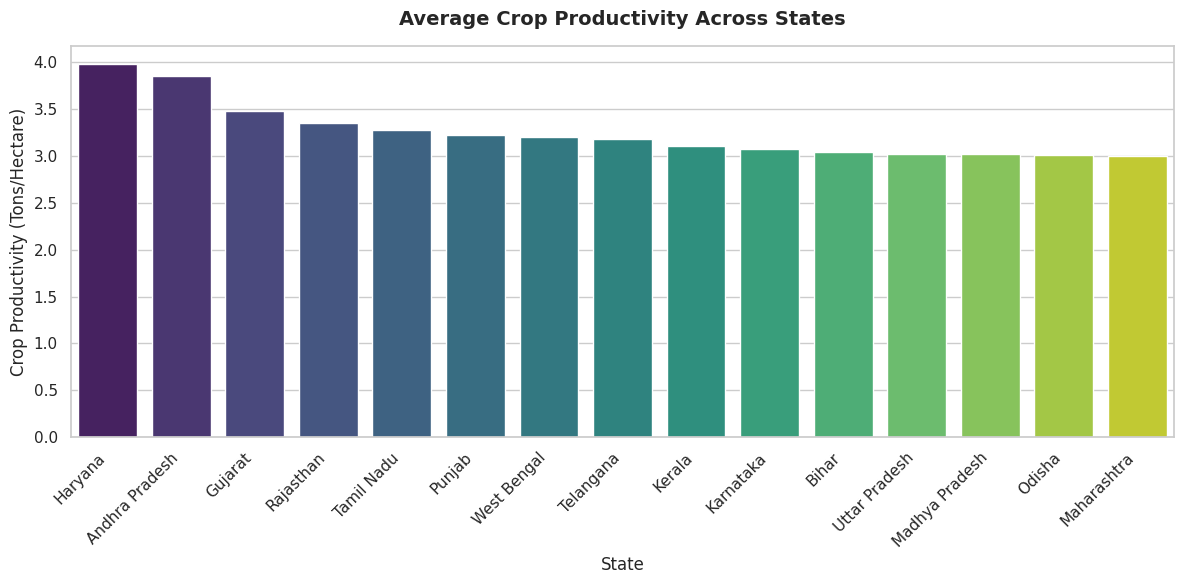

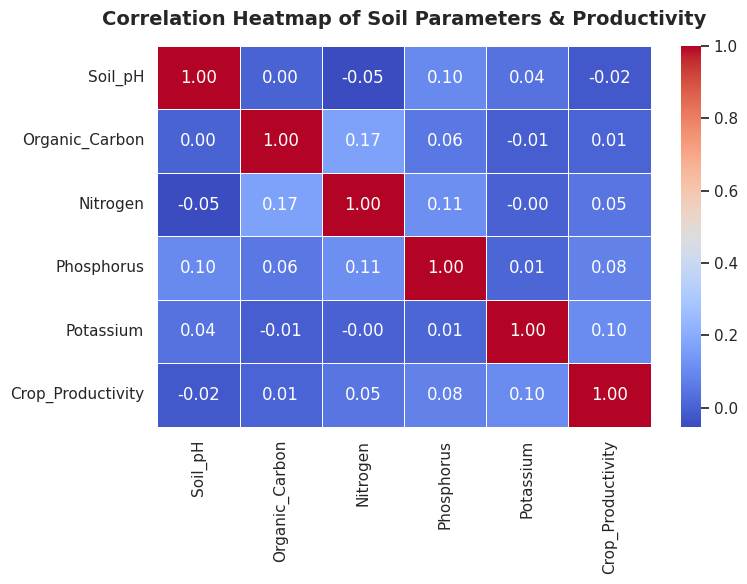

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style for our plots
sns.set_theme(style="whitegrid")

# --- Plot 1: Bar Chart of Average Crop Productivity by State ---
plt.figure(figsize=(12, 6))

# Calculate state averages again for plotting
state_prod = df.groupby('State')['Crop_Productivity'].mean().sort_values(ascending=False)

# Create the bar plot
ax = sns.barplot(x=state_prod.index, y=state_prod.values, palette="viridis", hue=state_prod.index, legend=False)

plt.title("Average Crop Productivity Across States", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("State", fontsize=12)
plt.ylabel("Crop Productivity (Tons/Hectare)", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# --- Plot 2: Correlation Heatmap ---
plt.figure(figsize=(8, 6))

# Select only our numerical columns for correlation
numerical_df = df[['Soil_pH', 'Organic_Carbon', 'Nitrogen', 'Phosphorus', 'Potassium', 'Crop_Productivity']]

# Compute correlation matrix
corr_matrix = numerical_df.corr()

# Draw the heatmap
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar=True)

plt.title("Correlation Heatmap of Soil Parameters & Productivity", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [7]:
# Calculate exact correlations and sort them against Crop Productivity
productivity_corr = numerical_df.corr()[['Crop_Productivity']].sort_values(by='Crop_Productivity', ascending=False)

print("--- Exact Correlation Values with Crop Productivity ---")
display(productivity_corr)

--- Exact Correlation Values with Crop Productivity ---


,Crop_Productivity
Crop_Productivity,1.000000
Potassium,0.104457
Phosphorus,0.080980
Nitrogen,0.049789
Organic_Carbon,0.008602
Soil_pH,-0.021443
